## Presentado por:

## Esteban Garcia Otalvaro

## Introducción al análisis frecuencial de señales

In [86]:
import pandas as pd
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.signal import welch
from scipy.io import loadmat

## Primero se probarán los códigos entregados en la guía para un enetendiiento más profundo de la práctica.

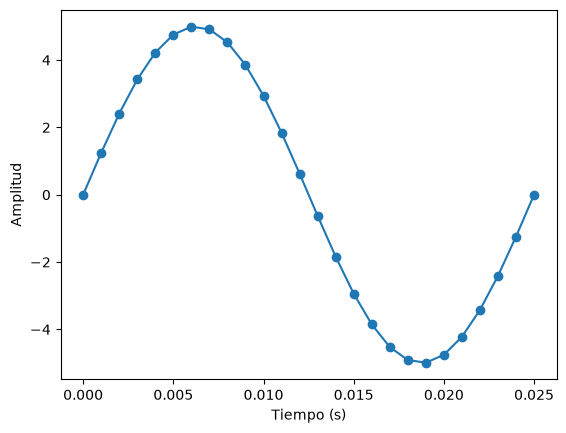

In [87]:
# Código base de la guía para entender la práctica
Fo = 40 # Frecuencia fundamental de la señal
Tp = 1/Fo # Periodo de la señal
Fs = 1000 # Frecuencia de muestreo
T = 1/Fs # Periodo de muestreo
t = np.arange(0, Tp+T, T) # Tiempo para un ciclo de la señal con duración de Tp más una muestra T
A = 5
x = A*np.sin(2*np.pi*Fo*t)
plt.plot(t, x, marker='o')
plt.xlabel('Tiempo (s)')
plt.ylabel('Amplitud')
plt.show()


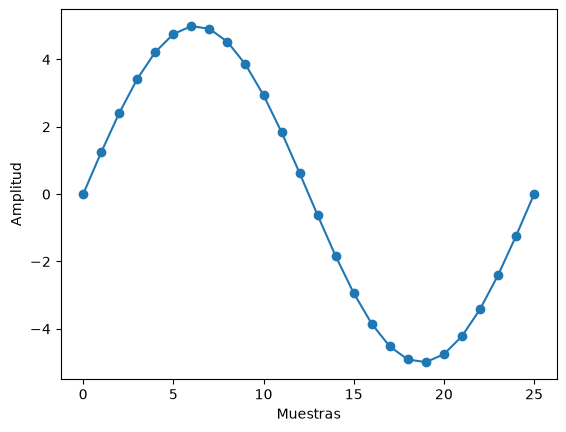

In [88]:
#Una manera alternativa de crear la señal 𝑥(𝑛) sería:
fo = Fo/Fs
n = np.arange(0, len(t))
x1 = A*np.sin(2*np.pi*fo*n)
plt.plot(n, x1, marker='o')
plt.xlabel('Muestras')
plt.ylabel('Amplitud')
plt.show()

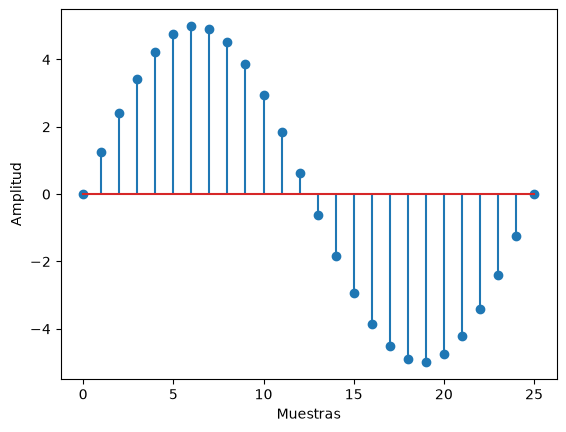

In [89]:
#a) Compruebe que los valores de las primeras cinco muestras son los mismos

plt.stem(n, x1)
plt.xlabel('Muestras')
plt.ylabel('Amplitud')
plt.show()


In [90]:
energia = sum(x**2)
potencia = energia/(len(t)-1)
#El valor cuadrático medio es la raíz cuadrada de la potencia:
rms = np.sqrt(potencia)
#Para hallar la energía, así como la potencia media de la señal considerando 10 ciclos de la sinusoide (250ms):
t10 = np.arange(0,10*Tp+T,T)
x10 = A*np.sin(2*np.pi*Fo*t10)
energia10 = sum(x10**2)
potencia10 = energia10/(len(t10)-1)
rms10 = np.sqrt(potencia10)


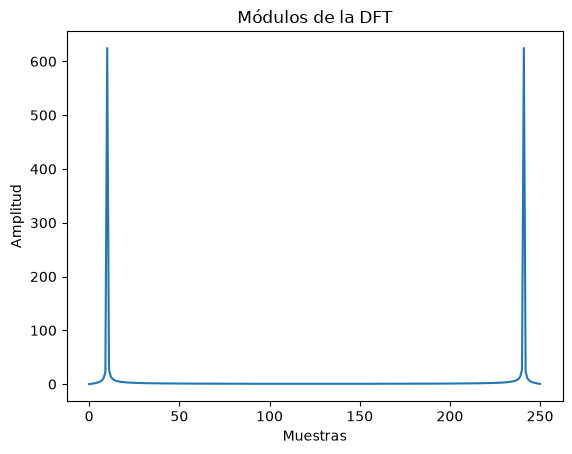

In [91]:
X10 = np.fft.fft(x10) #calcula en Python mediante el comando np.fft.fft
plt.plot(abs(X10))
plt.title('Módulos de la DFT')
plt.xlabel('Muestras')
plt.ylabel('Amplitud')
plt.show()

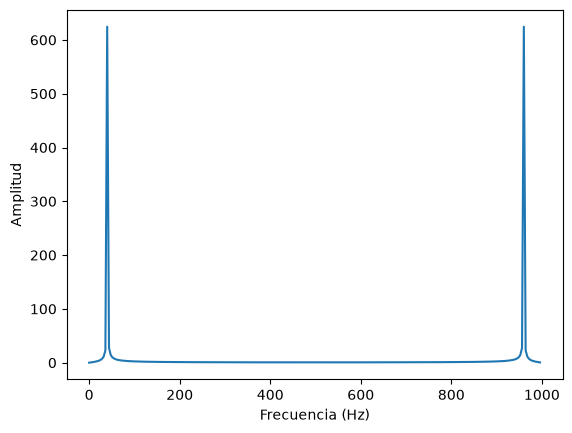

In [92]:
N = len(X10)
F = np.arange(0,N)*Fs/N
plt.plot(F,abs(X10))
plt.xlabel('Frecuencia (Hz)')
plt.ylabel('Amplitud')
plt.show()

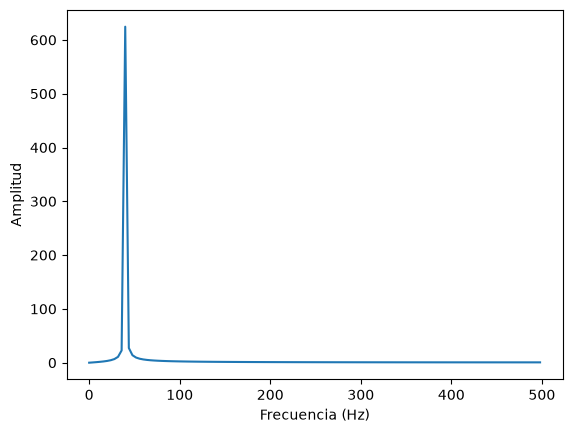

In [93]:
#Frecuencia Midad o Frecuencia de Nyquist
Nmitad = int(np.ceil(N/2))
Fmitad = np.arange(0,Nmitad)*Fs/N
X10mitad = X10[0:Nmitad]
plt.plot(Fmitad,abs(X10mitad))
plt.ylabel('Amplitud')
plt.xlabel('Frecuencia (Hz)')
plt.show()

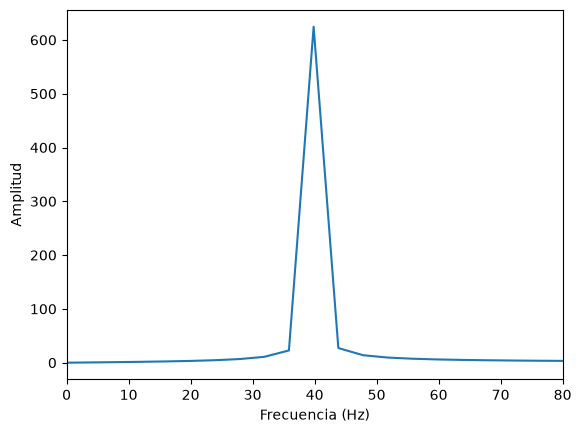

In [94]:
# Componente frecuencial se encuentra ubicada a 40 Hz
plt.plot(Fmitad,abs(X10mitad))
plt.ylabel('Amplitud')
plt.xlabel('Frecuencia (Hz)')
plt.xlim(0,80)
plt.show()

## Desarrollo de la práctica

**4.1 Cree una señal que sea la suma de tres componentes sinusoidales con frecuencias de 40,
80 y 160 Hz. Defina la frecuencia de muestreo mínima necesaria para representar la señal,
y utilice la frecuencia de muestreo necesaria para representarla apropiadamente. (10%)**

El teorema de Nyquist establece que la frecuencia de muestreo mínima debe ser mayor al doble de la frecuencia más alta presente en la señal ($F_s > 2F_{\max}$), en la práctica tomar exactamente esa tasa resulta insuficiente para representar adecuadamente la forma de la onda. Esto se debe a que se estarían tomando solo dos muestras por ciclo de la señal de mayor frecuencia, con lo que no es posible capturar con precisión la morfología sinusoidal ni sus variaciones de fase o amplitud (pudiendo incluso caer en los cruces por cero). Por esta razón, se recomienda utilizar una frecuencia de muestreo al menos 10 veces mayor que la frecuencia más alta de interés ($F_s = 1600\text{ Hz}$), lo que garantiza una mayor cantidad de datos por ciclo y, por tanto, una reconstrucción más fiel y visualmente clara de las señales [1].

Frecuencia de muestreo mínima (Nyquist): 320 Hz
Frecuencia de muestreo utilizada: 1600 Hz


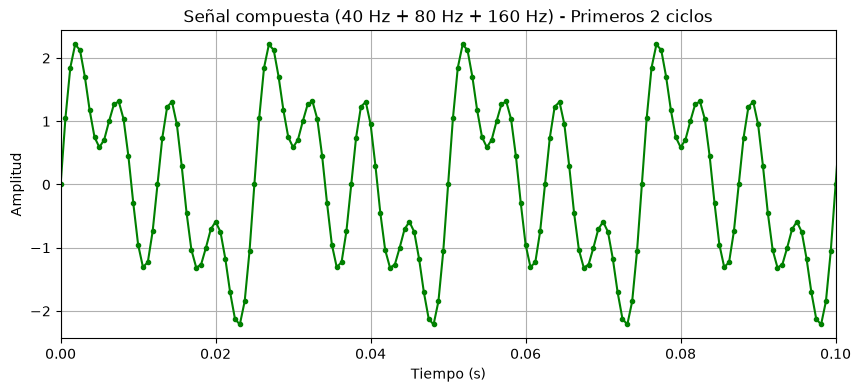

In [95]:
# Definición de frecuencias de muestreo
F_max = 160
Fs_min = 2 * F_max       # Frecuencia mínima de Nyquist: 320 Hz
Fs = F_max * 10          # Frecuencia adecuada elegida: 1600 Hz
T = 1 / Fs               # Periodo de muestreo
A = 1

print(f"Frecuencia de muestreo mínima (Nyquist): {Fs_min} Hz")
print(f"Frecuencia de muestreo utilizada: {Fs} Hz")

# Vector de tiempo para 10 periodos de la señal fundamental (40 Hz -> Tp = 0.025 s)
duracion = 10 * (1 / 40) # 0.25 segundos
t = np.arange(0, duracion, T)

# Señal de 40 Hz
Fo1 = 40
x1 = A * np.sin(2 * np.pi * Fo1 * t)

# Señal de 80 Hz
Fo2 = 80
x2 = A * np.sin(2 * np.pi * Fo2 * t)

# Señal de 160 Hz
Fo3 = 160
x3 = A * np.sin(2 * np.pi * Fo3 * t)

# Suma de las tres componentes
x = x1 + x2 + x3

# Gráfica en el dominio del tiempo (zoom a los primeros 0.1 s = 4 ciclos)
plt.figure(figsize=(10, 4))
plt.plot(t, x, marker='o', markersize=3, color='green')
plt.title('Señal compuesta (40 Hz + 80 Hz + 160 Hz) - Primeros 2 ciclos')
plt.xlabel('Tiempo (s)')
plt.ylabel('Amplitud')
plt.grid(True)
plt.xlim(0, 0.1)
plt.show()



**4.2 Calcule la transformada de Fourier de la señal y grafique el espectro de frecuencia.
Identifique en el espectro las frecuencias que componen la señal (trabaje con 10 periodos
de la señal). (10%)**


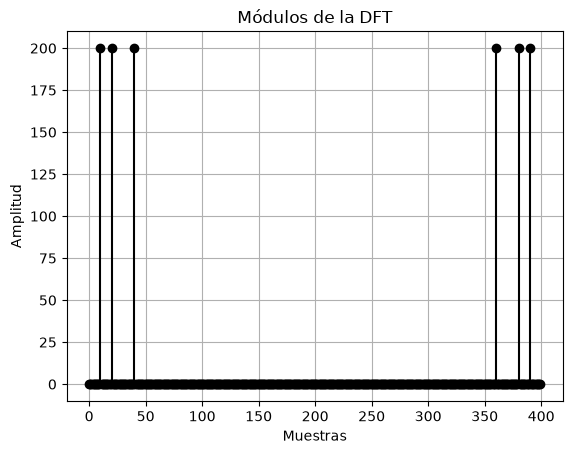

In [96]:
# 1. Espectro en función de las muestras (k)
X = np.fft.fft(x)
plt.stem(abs(X), linefmt='black', markerfmt='black', basefmt='black')
plt.title('Módulos de la DFT')
plt.xlabel('Muestras')
plt.ylabel('Amplitud')
plt.grid(True)
plt.show()

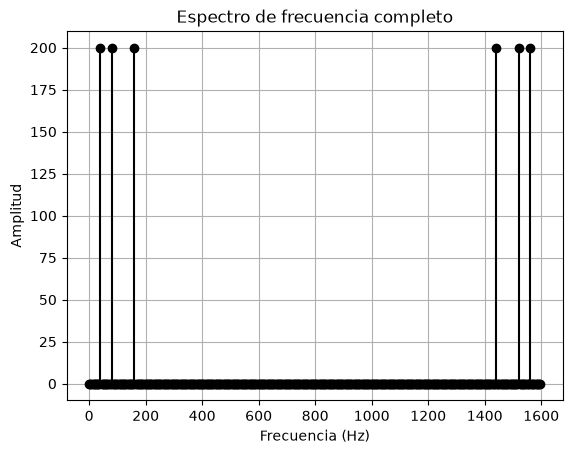

In [97]:
# 2. Espectro en función de la frecuencia completa (0 a Fs)
N = len(X)
F = np.arange(0, N) * Fs / N
plt.stem(F, abs(X), linefmt='black', markerfmt='black', basefmt='black')
plt.title('Espectro de frecuencia completo')
plt.xlabel('Frecuencia (Hz)')
plt.ylabel('Amplitud')
plt.grid(True)
plt.show()

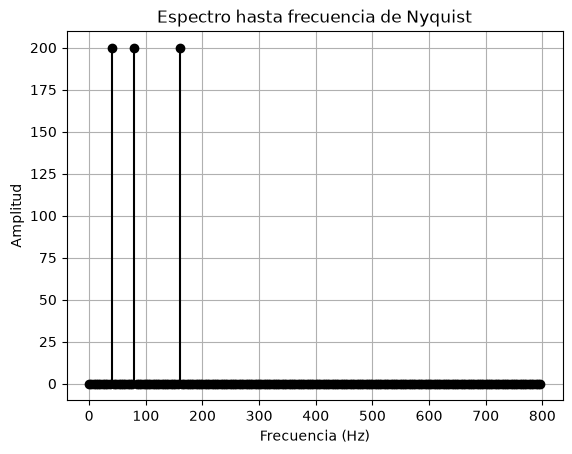

In [98]:
# 3. Espectro hasta la frecuencia de Nyquist (0 a Fs/2)
Nmitad = int(np.ceil(N / 2))
Fmitad = np.arange(0, Nmitad) * Fs / N
Xmitad = X[0:Nmitad]
plt.stem(Fmitad, abs(Xmitad), linefmt='black', markerfmt='black', basefmt='black')
plt.title('Espectro hasta frecuencia de Nyquist')
plt.ylabel('Amplitud')
plt.xlabel('Frecuencia (Hz)')
plt.grid(True)
plt.show()

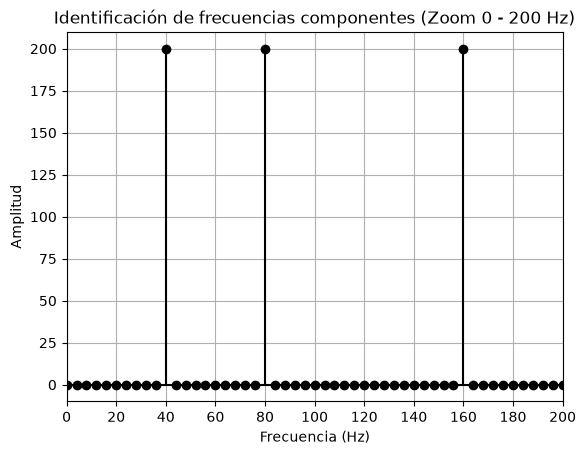

Frecuencia: 40 Hz | Índice k: 10 | Amplitud: 200.0
Frecuencia: 80 Hz | Índice k: 20 | Amplitud: 200.0
Frecuencia: 160 Hz | Índice k: 40 | Amplitud: 200.0


In [99]:
# 4. Zoom entre 0 y 200 Hz para identificar las componentes (40, 80 y 160 Hz)
plt.stem(Fmitad, abs(Xmitad), linefmt='black', markerfmt='black', basefmt='black')
plt.title('Identificación de frecuencias componentes (Zoom 0 - 200 Hz)')
plt.ylabel('Amplitud')
plt.xlabel('Frecuencia (Hz)')
plt.xlim([0, 200])
plt.xticks(np.arange(0, 201, 20))
plt.grid(True)
plt.show()

# Verificación numérica de los picos e índices k
indices_picos = np.where(np.abs(Xmitad) > 50)[0]
for k in indices_picos:
    print(f"Frecuencia: {Fmitad[k]:.0f} Hz | Índice k: {k} | Amplitud: {np.abs(Xmitad[k]):.1f}")

**4.3 Consulte la función que permite realizar el cálculo de la transformada inversa de Fourier.
Aplíquelo a la señal anterior. (10%)**

### Documentación de la función `numpy.fft.ifft`

La función de la librería **NumPy** encargada de calcular la Transformada Inversa Discreta de Fourier (IDFT) unidimensional mediante el algoritmo rápido IFFT (*Inverse Fast Fourier Transform*) es:

```python
numpy.fft.ifft(a, n=None, axis=-1, norm=None, out=None)
```

---

#### Parámetros

* **`a`** (`array_like`): Arreglo de entrada que representa la señal en el dominio de la frecuencia (generalmente el espectro complejo obtenido previamente mediante `np.fft.fft`). Debe ser un array complejo o convertible a complejo; si se suministra un arreglo real o entero, NumPy lo convierte automáticamente a tipo complejo antes de ejecutar el algoritmo. Para obtener una reconstrucción correcta, `a` debe conservar el orden estándar de la DFT (componente DC o 0 Hz en el índice `0`, frecuencias positivas en la primera mitad y frecuencias negativas en la segunda mitad).

* **`n`** (`int`, *opcional*): Longitud deseada del eje transformado en la señal de salida:
  * Si `n` es **mayor** que la longitud de `a`, el espectro se rellena con ceros al final (*zero-padding*), lo que equivale a interpolar la señal resultante en el dominio del tiempo.
  * Si `n` es **menor** que la longitud de `a`, se recorta (trunca) `a` a los primeros `n` elementos antes de realizar el cálculo.
  * Si `n` es `None` (*por defecto*), la salida conserva exactamente la misma longitud de la entrada `a`.

* **`axis`** (`int`, *opcional*): Eje del arreglo sobre el cual se calcula la IFFT cuando se trabaja con estructuras multidimensionales (por ejemplo, matrices que almacenan múltiples canales o ventanas de una bioseñal). Por defecto es `-1` (el último eje del arreglo).

* **`norm`** (`{None, "ortho"}`, *opcional*): Define el tipo de normalización entre el dominio del tiempo y el de la frecuencia:
  * `None` (*por defecto*, equivalente a `"backward"`): La IFFT aplica el factor de escala $1/N$ (compensando que `np.fft.fft` no está normalizada), lo que permite recuperar la amplitud física original de la señal en el dominio del tiempo.
  * `"ortho"`: Aplica normalización ortonormal, escalando tanto la transformada directa como la inversa por $1/\sqrt{N}$ para preservar la energía total entre ambos dominios.

---

#### Salida

* **`out`** (`ndarray` de números complejos): Devuelve la transformada inversa discreta de Fourier de `a` reconstruida en el dominio del tiempo. El resultado es siempre un arreglo de tipo complejo (`complex128`), incluso si la señal original antes de la transformada directa era puramente real, debido a pequeños residuos numéricos de punto flotante en la parte imaginaria (del orden de $10^{-16}$). Por esta razón, se toma su parte real mediante `np.real()` al momento de graficar o procesar la señal reconstruida, evitando advertencias de conversión de tipo [2].


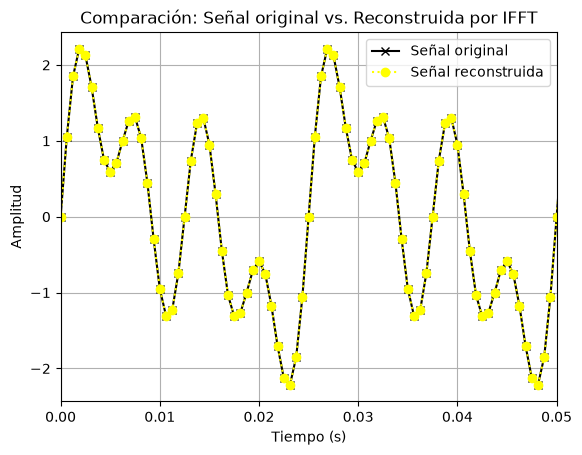

Error máximo de reconstrucción: 1.33e-15


In [108]:
# Cálculo de la Transformada Inversa de Fourier (IFFT)
x_inv = np.fft.ifft(X)

# Gráfica comparativa entre la señal original y la reconstruida
plt.plot(t, x, marker='x', color='black', label='Señal original')
plt.plot(t, np.real(x_inv), marker='o', color='yellow', label='Señal reconstruida', linestyle='dotted')
plt.title('Comparación: Señal original vs. Reconstruida por IFFT')
plt.xlim(0, 0.05)  # Zoom a 2 periodos (50 ms) para visualizar la coincidencia exacta de los puntos
plt.legend()
plt.xlabel('Tiempo (s)')
plt.ylabel('Amplitud')
plt.grid(True)
plt.show()

# Verificación numérica del error máximo de reconstrucción
error_max = np.max(np.abs(x - np.real(x_inv)))
print(f"Error máximo de reconstrucción: {error_max:.2e}")

**4.4 ¿Podría decir que las siguientes líneas aplican un filtro? ¿Por qué? (10%)**
F1 = np.fft.fft(x);

F2 = np.zeros((len(F1)));

F2[9:13] = F1[9:13];

xr = np.fft.ifft(F2);

fig = plt.figure()

ax = fig.add_subplot(111)

ax.plot(t, np.real(xr))

Introducción al análisis frecuencial de señales Bioseñales y sistemas

ax.set(xlabel='Tiempo (s)', ylabel='Amplitud (V)');

plt.show()

**Extraiga de manera similar cada una de las componentes de la señal.**



**Sí, las líneas de código implementan un filtro digital ideal pasa-banda en el dominio de la frecuencia.** 

El procedimiento equivale a multiplicar el espectro de la señal $X(k)$ por una función de transferencia rectangular $H(k)$ cuya ganancia es $1$ dentro de una banda de frecuencias específica (banda de paso) y $0$ fuera de ella (banda de rechazo). Este proceso se ejecuta en cuatro etapas:

1. **Transformación al dominio espectral (`F1 = np.fft.fft(x)`):** Descompone la señal temporal compuesta en sus coeficientes complejos de Fourier $X(k)$[cite: 7, 10]. Cada índice $k$ representa una frecuencia discreta dada por $f_k = \frac{k \cdot F_s}{N}$[cite: 8].
2. **Creación de la máscara espectral (`F2 = np.zeros(...)`):** Al inicializar un arreglo de ceros de la misma longitud $N$, se establece una atenuación total para todas las componentes frecuenciales por defecto[cite: 10].
3. **Selección de la banda de paso (`F2[9:13] = F1[9:13]`):** Para nuestra señal ($N = 400$ muestras y $F_s = 1600\text{ Hz}$), la resolución en frecuencia es $\Delta f = \frac{1600}{400} = 4\text{ Hz/índice}$. Por lo tanto, conservar los índices $k \in [9, 12]$ equivale a permitir únicamente el paso de frecuencias entre $36\text{ Hz}$ y $48\text{ Hz}$, aislando exclusivamente la componente de **$40\text{ Hz}$** ($k = 10$) y eliminando por completo las componentes de $80\text{ Hz}$ ($k = 20$) y $160\text{ Hz}$ ($k = 40$)[cite: 10].
4. **Síntesis temporal (`xr = np.fft.ifft(F2)`):** Al aplicar la transformada inversa de Fourier sobre el espectro filtrado `F2` y tomar su parte real (`np.real(xr)`), se reconstruye en el dominio del tiempo únicamente la onda sinusoidal aislada[cite: 10].

#### 2. Observaciones técnicas del algoritmo

* **Preservación de fase (`dtype=complex`):** En el fragmento original de la guía, `np.zeros(len(F1))` crea un arreglo de números reales (`float64`), lo que descarta la parte imaginaria de `F1` (información de fase) y arroja una advertencia (`ComplexWarning`). Al definir `dtype=complex`, se conserva tanto la magnitud como la fase original de la sinusoide.
* **Simetría hermítica y amplitud:** Si únicamente se copian los índices positivos (`9:13`) y se dejan en cero sus frecuencias negativas simétricas ($N - k$), la energía del espectro se reduce a la mitad y la señal reconstruida tiene amplitud $0.5\text{ V}$. Al conservar también la banda simétrica conjugada en la segunda mitad del espectro, se recupera la amplitud física completa de $1.0\text{ V}$[cite: 7, 8].

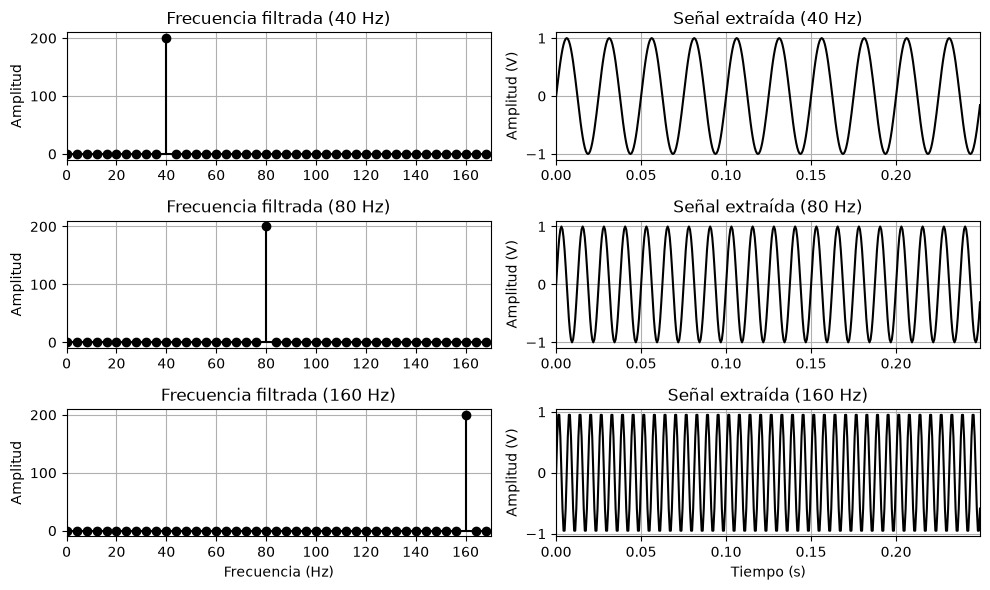

In [109]:
N = len(X)

# Índices correspondientes a 40 Hz, 80 Hz y 160 Hz
idx_40 = int(np.round(40 * N / Fs))
idx_80 = int(np.round(80 * N / Fs))
idx_160 = int(np.round(160 * N / Fs))

# Crear espectros vacíos para cada componente
Xfilt_40 = np.zeros(N, dtype=complex)
Xfilt_80 = np.zeros(N, dtype=complex)
Xfilt_160 = np.zeros(N, dtype=complex)

# Copiar la frecuencia positiva y su conjugado simétrico
Xfilt_40[idx_40] = X[idx_40]
Xfilt_40[-idx_40] = np.conj(X[idx_40])

Xfilt_80[idx_80] = X[idx_80]
Xfilt_80[-idx_80] = np.conj(X[idx_80])

Xfilt_160[idx_160] = X[idx_160]
Xfilt_160[-idx_160] = np.conj(X[idx_160])

# Transformada inversa para obtener las señales en el dominio del tiempo
senal_40 = np.fft.ifft(Xfilt_40).real
senal_80 = np.fft.ifft(Xfilt_80).real
senal_160 = np.fft.ifft(Xfilt_160).real

# Graficar los espectros filtrados y las señales reconstruidas
plt.figure(figsize=(10, 6))

plt.subplot(3, 2, 1)
plt.stem(Fmitad, abs(Xfilt_40[:N//2]),
         linefmt='black', markerfmt='ko', basefmt='black')
plt.title('Frecuencia filtrada (40 Hz)')
plt.ylabel('Amplitud')
plt.xlim(0, 170)
plt.grid(True)

plt.subplot(3, 2, 2)
plt.plot(t, senal_40, color='black')
plt.title('Señal extraída (40 Hz)')
plt.ylabel('Amplitud (V)')
plt.xlim(0, np.max(t))
plt.grid(True)

plt.subplot(3, 2, 3)
plt.stem(Fmitad, abs(Xfilt_80[:N//2]),
         linefmt='black', markerfmt='ko', basefmt='black')
plt.title('Frecuencia filtrada (80 Hz)')
plt.ylabel('Amplitud')
plt.xlim(0, 170)
plt.grid(True)

plt.subplot(3, 2, 4)
plt.plot(t, senal_80, color='black')
plt.title('Señal extraída (80 Hz)')
plt.ylabel('Amplitud (V)')
plt.xlim(0, np.max(t))
plt.grid(True)

plt.subplot(3, 2, 5)
plt.stem(Fmitad, abs(Xfilt_160[:N//2]),
         linefmt='black', markerfmt='ko', basefmt='black')
plt.title('Frecuencia filtrada (160 Hz)')
plt.xlabel('Frecuencia (Hz)')
plt.ylabel('Amplitud')
plt.xlim(0, 170)
plt.grid(True)

plt.subplot(3, 2, 6)
plt.plot(t, senal_160, color='black')
plt.title('Señal extraída (160 Hz)')
plt.xlabel('Tiempo (s)')
plt.ylabel('Amplitud (V)')
plt.xlim(0, np.max(t))
plt.grid(True)

plt.tight_layout()
plt.show()

**4.5 Cree una función que calcule manualmente el periodograma de Welch de una señal discreta
(usando la DFT), explique paso a paso el algoritmo. Pruébelo en una de las señales
construidas anteriormente.**


In [101]:
"""Periodograma de Welch
Método de Welch donde calcula la densidad espectral de potencia en una ventana que se desplaza a lo largo de la señal.
y finalmente sepromedian los espectros de potencia para obtener un periodograma de Welch."""
#@title Default title text
#importamos la rutina de welch
from scipy.signal import welch as pwelch

#%% USANDO WELCH
fs = 1000 # frecuencia de muestreo
nperseg = 2000 #ancho de la ventana
noverlap = int(nperseg/2) #solapamiento de las ventanas
f, Pxx = pwelch(X[0,:], fs, 'hanning', nperseg, noverlap)
#graficamos frecuencia vs potencia
plt.stem(f, Pxx)
plt.xlabel('Frecuencia')
plt.ylabel('Potencia')
plt.xlim([0, 50]) #rango para el eje X
plt.show()


IndexError: too many indices for array: array is 1-dimensional, but 2 were indexed

**4.6 El archivo adjunto (senecg.mat) contiene una señal de ECG adquirida a una frecuencia de
muestreo de 250 Hz. Realice un análisis en frecuencia de la señal usando periodogramas
de Welch y determine si es necesario eliminar ruido, en tal caso, elimínelo de la forma que
se mostró antes y compruebe que lo haya realizado, calcule la transformada inversa de
Fourier de la señal filtrada y compruebe con el periodograma. (Usar una ventana Hanning,
y justificar la elección del solapamiento y el ancho de la ventaja) (25%). Compare el
método de la librería con la función creada en el punto anterior.**

**4.7 Realice un análisis de frecuencia a través del periodograma de welch de una señal de EKG
de un paciente Sano y otra de un paciente con alguna condición cardiaca que en el proyecto
1 hayan identificado que presentaba diferencias, si no encontró diferencias, elija un par al
azar. Realice un análisis comparativo de las señales según lo que le indiquen los
periodogramas. (Usar una ventana Hanning, y justificar la elección del solapamiento y el
ancho de la ventana) (25%)**


**4.8 Conclusiones y referencias (10%)**

## Conclusiones

## Referencias Bibliográficas

[1]Siemens Simcenter. (2020, agosto 29). Digital Signal Processing: Sampling Rates, Bandwidth, Spectral Lines, and more. Siemens Community. https://community.sw.siemens.com/s/article/digital-signal-processing-sampling-rates-bandwidth-spectral-lines-and-more

[2]NumPy Developers. (2024). numpy.fft.ifft — NumPy v2.2 Manual. NumPy. https://numpy.org/doc/2.2/reference/generated/numpy.fft.ifft.html

[3] Morais, E., Queiroz, D. M., Garcia, A. R., Silva, D. C., & Silva, D. G. (2024). Use of digital signal processing and machine learning to classify electrocardiographic signals obtained with dry electrodes. Smart Health https://www-sciencedirect-com.udea.lookproxy.com/science/article/pii/S2950435X24000143

[4] D. J. Hernández-González, I. Flores-Cruz, and J. A. Hernández-González, "Detección de señales EEG epilépticas utilizando redes convolucionales basada en la transformada synchrosqueezing acolchadas, vol. 25, no. 2, pp. 269–278, 2021. [Online]. Available: https://www.scielo.org.mx/scielo.php?script=sci_arttext&pid=S1405-55462021000200269